<a href="https://colab.research.google.com/github/dairxp/Py-Colab-ALD/blob/main/01_Deep_Learning_Red_Neuronal_XOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Predicción XOR**
|A|B|C|Y|
|:---|:---|:---|:---|
|0|0|0|0|
|0|0|1|1|
|0|1|0|1|
|0|1|1|0|
|1|0|0|1|
|1|0|1|0|
|1|1|0|0|
|1|1|1|1|

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
x = np.array(([0,0,0],
              [0,0,1],
              [0,1,0],
              [0,1,1],
              [1,0,0],
              [1,0,1],
              [1,1,0],
              [1,1,1]), dtype=float)
y = np.array(([0],
              [1],
              [1],
              [0],
              [1],
              [0],
              [0],
              [1]), dtype=float)

In [ ]:
print(x)

[[0. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 1.]
 [1. 0. 0.]
 [1. 0. 1.]
 [1. 1. 0.]
 [1. 1. 1.]]


In [ ]:
print(y)

[[0.]
 [1.]
 [1.]
 [0.]
 [1.]
 [0.]
 [0.]
 [1.]]


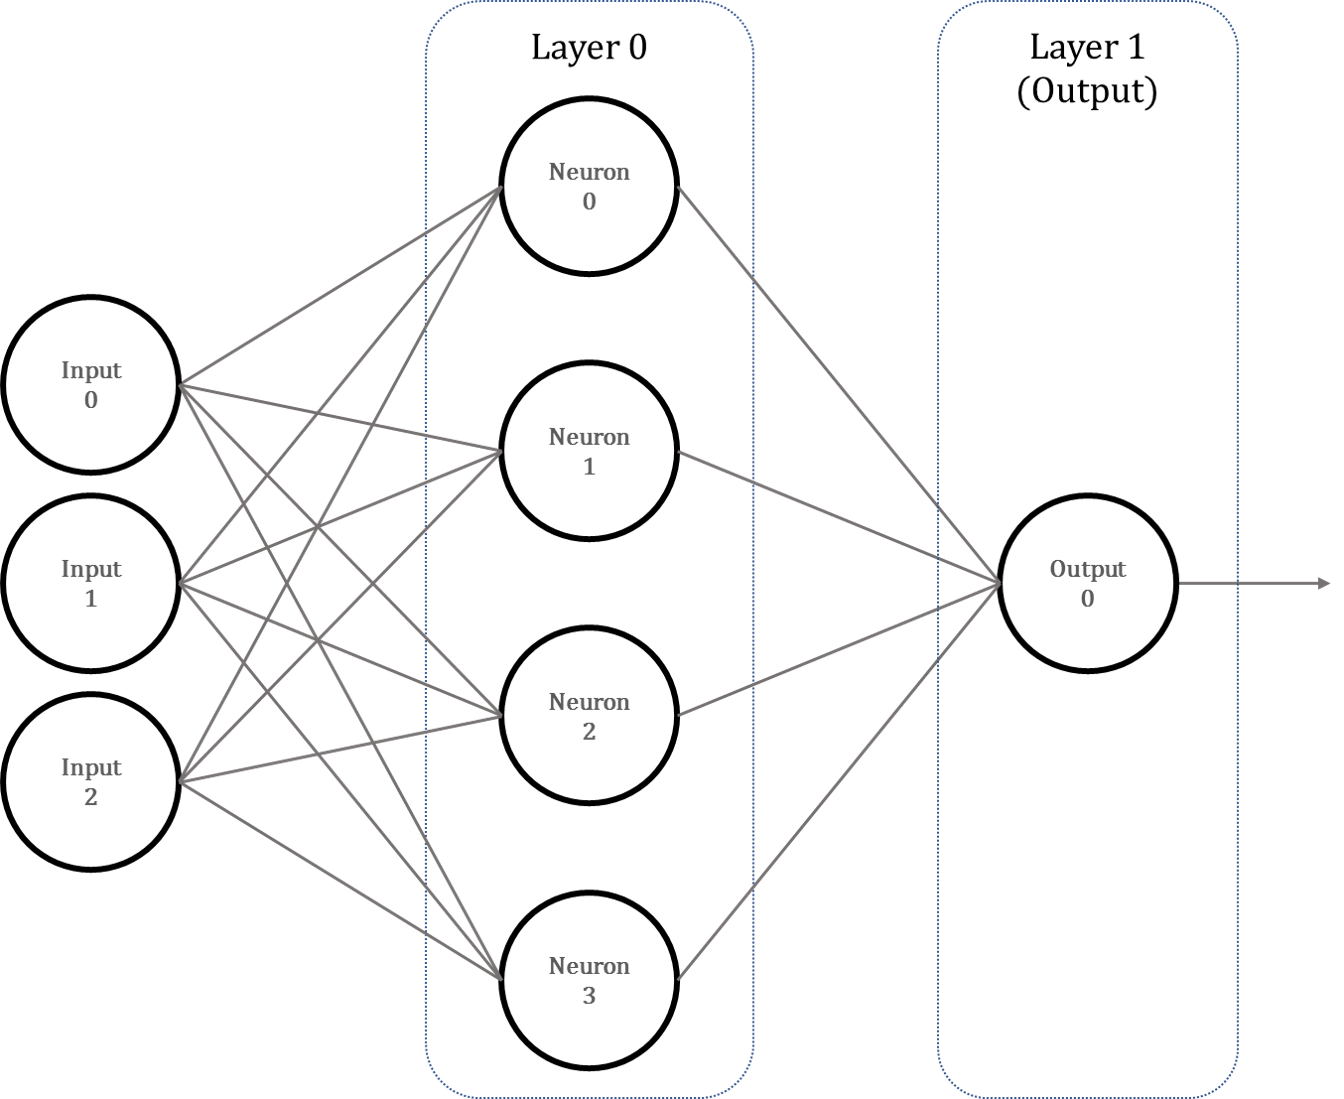

In [ ]:
# inicializar las variables
lr = 0.5
w0 = np.random.randn(x.shape[1], 4)
w1 = np.random.randn(4, 1)
output = np.zeros(y.shape)

z0, z1, a0, a1, a2, errors = [], [], [], [], [], []

In [ ]:
w0

array([[ 0.27710474, -1.1877361 , -0.97477299,  0.7225495 ],
       [ 0.68708637,  0.7326401 , -1.7866592 ,  0.08300937],
       [-0.62424881,  0.51822642, -1.03446456,  0.22073499]])

In [ ]:
w1

array([[ 0.20592794],
       [-1.26078119],
       [-2.11404624],
       [-1.21357933]])

In [ ]:
output

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [ ]:
def sigmoid(t):
  return 1/(1+np.exp(-t))

def sigmoid_derivative(p):
  return sigmoid(p) * sigmoid(1-p)

In [ ]:

def feedforward(x_input):

    #np.dot regresa el producto punto de dos arreglos.
    global a0, z0, a1, z1, a2

    # La activación de la capa cero, es la entrada.
    a0 = x_input
    z0 = np.dot(a0, w0) # NOTA: En esta sección se sumarían los bias si existieran.

    # La activación de la capa uno, es la información de las neuronas anteriores (Entradas)
    # a través de la función de activación "sigmoid".
    a1 = sigmoid(z0)
    z1 = np.dot(a1, w1)

    # La activación de la capa dos, es la información de las neuronas anteriores (Capa 1)
    # a través de la función de activación "sigmoide".
    a2 = sigmoid(z1)

    # En esta red, aquí terminamos, porque no hay más capas.
    output = a2

    return output

In [ ]:
def backprop():
    # Aplicando la regla de la cadena para la función de perdida respecto a los pesos 2 y 1.
    # .T devuelve la matriz traspuesta
    global w0, w1, w2, b0, b1, b2

    # Calcular el error MSE --> Mean Square Error.
    mse = np.sum( (1 / 2) * (y - output) * (y - output))
    errors.append(mse)

    delta1 = -(y - output) * sigmoid_derivative(z1)
    d_w1 = np.dot(a1.T,delta1)
    d_b1 = delta1

    delta0 = np.dot(delta1,w1.T) * sigmoid_derivative(z0)
    d_w0 = np.dot(a0.T,delta0)
    d_b0 = delta0

    # lr --> Learning Rate, es un parametro propuesto por el investigador
    # que indica que tanta importancia le asignamos a los errores del pasado.
    w1 = w1 - lr * d_w1
    w0 = w0 - lr * d_w0

In [ ]:
# Sesión de entrenamiento
repeticiones = 1000

for i in range(repeticiones):
    # Primero se realiza el feedforward y despues el back propagation
    output = feedforward(x)

    backprop()
    # Las siguientes líneas muestran el error cada 10 sesiones.
    if i % 10 == 0:
        print("Epoch: {}, mse: {}".format(i,errors[-1]))

Epoch: 0, mse: 1.4657666507900773
Epoch: 10, mse: 1.019298812715407
Epoch: 20, mse: 1.003337310878305
Epoch: 30, mse: 0.9940381953898261
Epoch: 40, mse: 0.9868568138422837
Epoch: 50, mse: 0.9807766348188091
Epoch: 60, mse: 0.9751556934177315
Epoch: 70, mse: 0.9695793905941164
Epoch: 80, mse: 0.9637800503753108
Epoch: 90, mse: 0.9575899192286719
Epoch: 100, mse: 0.9509150677501649
Epoch: 110, mse: 0.9437213549894238
Epoch: 120, mse: 0.9360251323822861
Epoch: 130, mse: 0.9278833409974312
Epoch: 140, mse: 0.9193810559507343
Epoch: 150, mse: 0.9106179438231143
Epoch: 160, mse: 0.9016963908059277
Epoch: 170, mse: 0.8927129767136145
Epoch: 180, mse: 0.8837532364257985
Epoch: 190, mse: 0.8748888124329521
Epoch: 200, mse: 0.866176246510133
Epoch: 210, mse: 0.8576570502478684
Epoch: 220, mse: 0.849358838404876
Epoch: 230, mse: 0.8412972223627857
Epoch: 240, mse: 0.8334780464358661
Epoch: 250, mse: 0.8258995204204391
Epoch: 260, mse: 0.8185538564286288
Epoch: 270, mse: 0.8114281097548705
Epoch: 

In [ ]:
w0

array([[ 0.49359949, -9.09739325, -5.07982949, -1.73144997],
       [-1.75058402,  6.39349396, -5.67913223,  1.20937456],
       [-2.1586207 ,  6.39634886, -5.66373916,  1.03418182]])

In [ ]:
w1

array([[  6.43405929],
       [  8.37101747],
       [ -9.46046819],
       [-10.0290145 ]])

##Usemos la red para predecir una entrada

In [ ]:
# La salida es igual a la predicción de la red ante una entrada.
output = feedforward([1,1,1])
output

# [1,0,1] --> [0.1438337]  --> 0
# [0,0,1] --> [0.83087144] --> 1
# [0,1,0] --> [0.82529912] --> 1
# [1,1,0] --> [0.14376737] --> 0
# [1,1,1] --> [0.89100881] --> 1

array([0.89100881])

##Grafiquemos los errores.

Entrada propuesta $x = [1,0,1]$
<br>Salida esperada $y=0$ (Debido a que tiene un número Par de unos).

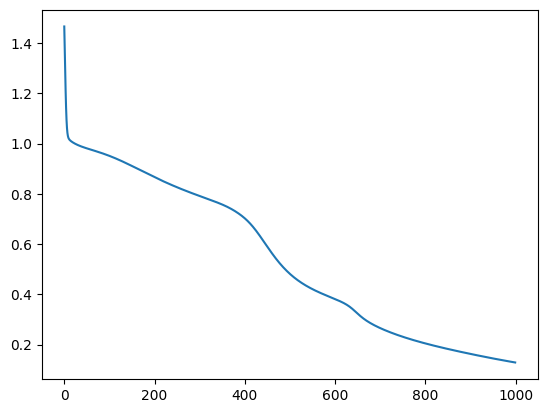

In [ ]:
plt.plot(errors);

## ¿Cómo podemos mejorar el desempeño?

No existe una alternativa única pero se pueden intentar las siguientes alternativas:
1) Incrementar la sesiones de entrenamiento.
2) Experimentar modificando el valor de la taza de aprendizaje (𝑙𝑟).
3) Proponer otra configuración de red neuronal.
4) Incluir Bias.